## Задача регрессии
Датасет Wine Quality, работаем с подмножеством красных вин (current = red + white): 
- целевая переменная— quality 


In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

%matplotlib inline
sns.set_theme(style="darkgrid")

from ucimlrepo import fetch_ucirepo 
  
wine_quality = fetch_ucirepo(id=186)
url = wine_quality.metadata.data_url
df = pd.read_csv(url, sep=",")
df['color'] = df['color'].map({'red': 0, 'white': 1})

# url = "wine_quality/winequality-red.csv"
# df = pd.read_csv(url, sep=";")


print(df.shape)
display(df.head())
display(df["quality"].describe())

(6497, 13)


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality,color
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,0
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0


count    6497.000000
mean        5.818378
std         0.873255
min         3.000000
25%         5.000000
50%         6.000000
75%         6.000000
max         9.000000
Name: quality, dtype: float64

Признаки в разных масштабах: 
* chlorides ~0.01–0.6
* total sulfur dioxide до 289
* alcohol 8–15 
> Коэффициенты «сырые»: LR несравнимы между собой, для этого используем масштабирование StandardScaler в пайплайне. 

*quality*: среднее 5.64, std 0.81, диапазон 3–8 — оценка дискретна

Далее проверим **пропуски** в признаках и **дублирование** объектов

Количество пропусков в каждом столбце:


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality,color
missing_values,0,0,0,0,0,0,0,0,0,0,0,0,0


Количество полных дубликатов строк: 1177
Строк после удаления дубликатов: 5320


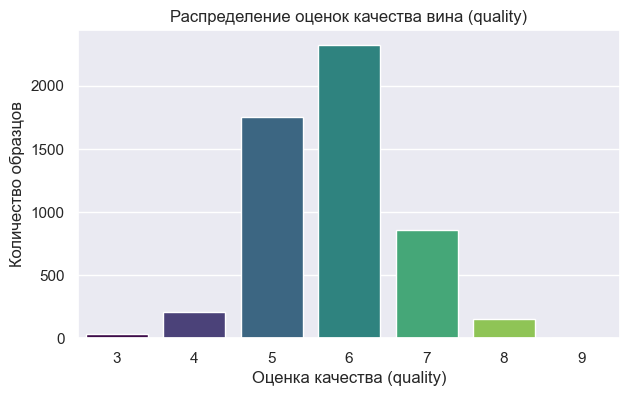

In [2]:
print("Количество пропусков в каждом столбце:")
display(df.isna().sum().to_frame(name="missing_values").T)

print(f"Количество полных дубликатов строк: {df.duplicated().sum()}")
df = df.drop_duplicates().reset_index(drop=True)
print(f"Строк после удаления дубликатов: {df.shape[0]}")

plt.figure(figsize=(7, 4))
ax = sns.countplot(data=df, x="quality", hue="quality", palette="viridis", legend=False)
plt.title("Распределение оценок качества вина (quality)")
plt.xlabel("Оценка качества (quality)")
plt.ylabel("Количество образцов")
plt.show()

Распределение целевого признака преобладает в районе 5-6. Последствия: модель будет систематически смещать редкие классы к среднему — проверим это в анализе ошибок. Проверим корреляцию признаков с целевой переменной.

In [3]:
corr_matrix = df.corr()

quality_corr = corr_matrix[["quality"]].sort_values(by="quality", ascending=False)
print("Корреляция признаков с целевой переменной quality:")
display(quality_corr.style.background_gradient(cmap="coolwarm", vmin=-1, vmax=1).format("{:.4f}"))

Корреляция признаков с целевой переменной quality:


,quality
quality,1.0000
alcohol,0.4694
color,0.1148
citric_acid,0.0980
free_sulfur_dioxide,0.0540
sulphates,0.0419
pH,0.0397
total_sulfur_dioxide,-0.0503
residual_sugar,-0.0568
fixed_acidity,-0.0801


Видим: alcohol 0.48 — сильнейший положительный предиктор, volatile acidity −0.40 — уксусная кислота. Но все признаки r: |r| < 0.5 → линейная связь умеренная, значит у нелинейных моделей есть преимущество. 

Рассмотрим корреляционную матрицу между всеми признаками:

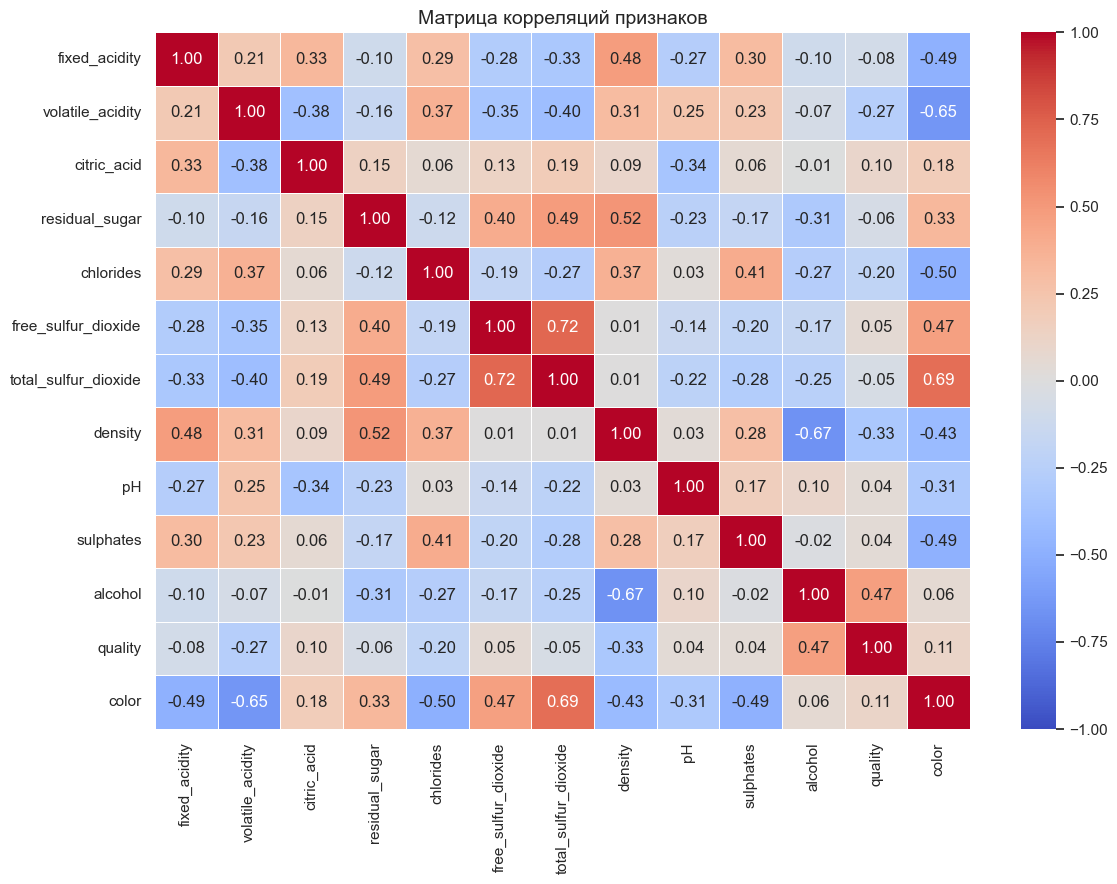

In [4]:
plt.figure(figsize=(12, 9))

mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1, vmax=1,
    linewidths=0.5
)

plt.title("Матрица корреляций признаков", fontsize=14)
plt.tight_layout()
plt.show()

Мультиколлинеарность: 
1. fixed acidity ↔ citric acid ≈ +0.67
2. fixed acidity ↔ pH ≈ −0.69
3. fixed acidity ↔ density ≈ +0.67
4. free sulfur dioxide ↔ total sulfur dioxide ≈ +0.67
5. density ↔ alcohol ≈ −0.50

Два следствия: 
1. коэффициенты LR по таким признакам нестабильны и могут получать «неправильные» знаки
2. полиномиальные признаки усилят эту проблему → нужна регуляризация (Ridge)

### <u> Выводы по первичному анализу данных </u>

Датасет — 1599 красных вин (после удаления 240 полных дубликатов — 1359), 11 физико-химическихпризнаков и целевая quality (оценки 3–8). Пропусков нет. Дубликаты удалены до разбиения: если бы одинаковые строки попали и в train, и в test, оценка качества была бы оптимистично смещённой.

Целевая переменная сильно несбалансирована: классы 5–6 — ~82% данных, а крайние оценки 3 и 8 —лишь 10 и 17 объектов. Модели будет сложно научиться предсказывать редкие крайние качества —там стоит ждать наибольших ошибок.

Сильнейшие связи с quality: 
1. alcohol (+0.48) 
2. volatile acidity (−0.40) 

Обе осмысленны: спиртделает вкус «полнее», летучая кислотность — признак дефекта (уксусный привкус).

Теплокарта показывает мультиколлинеарность — это осложнит интерпретацию коэффициентов линейной регрессии.

## Подготовка выборок

In [5]:
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42

X = df.drop(columns=["quality"])
y = df["quality"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

print(X_train.shape, X_test.shape)

(4256, 12) (1064, 12)


Разбиение **80/20** (train 1087 / test 272), **random_state=19** зафиксирован — экспериментвоспроизводим. 

20% — компромисс: 272 объекта достаточно для устойчивой финальной оценки, при этом в обучении остаётся максимум данных. Разбиение случайное, без стратификации: quality — числовая цель, а не метка класса, распределения в train и test сопоставимы.

Тестовая выборка используется строго один раз — для финальной оценки.
Все решения по моделям и параметрам будут приниматься по 5-блочной кросс-валидации на train. При многократной оценке на одном и том же тесте информация из него «просачивается» в выбор модели: оценка становится оптимистичной, а на новых данных модель работает хуже заявленного.

## Обучение

**Baseline** — константа. 
- Для RMSE оптимальная константа — среднее train (5.64): E(y−c)² минимальна при c = E(y); 
- для MAE оптимальна медиана. 
- Baseline (RMSE 0.86) — планка: если модель не лучше, признаки не несут информации. 


#### MAE vs RMSE

* MAE — средняя абсолютная ошибка, все ошибки равноправны, устойчива к выбросам
* RMSE - возводит ошибки в квадрат: промах в 2 балла «стоит» как 4 промаха по 1 → RMSE ≥ MAE всегда



In [6]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import root_mean_squared_error, mean_absolute_error
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score, GridSearchCV


def rmse(y_true, y_pred):
    return root_mean_squared_error(y_true, y_pred)

def mae(y_true, y_pred):
    return mean_absolute_error(y_true, y_pred)

grid = GridSearchCV(
    Pipeline([
        ("poly", PolynomialFeatures(include_bias=False)),
        ("scaler", StandardScaler()),
        ("model", Ridge()),
    ]),
    param_grid={
        "poly__degree": [1, 2, 3],
        "model__alpha": [0.01, 0.1, 1, 10, 100, 1000],
    },
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
)
grid.fit(X_train, y_train)

best_degree = grid.best_params_["poly__degree"]
best_alpha = grid.best_params_["model__alpha"]

baseline = DummyRegressor(strategy="mean")
lin_reg = Pipeline([(
    "scaler", StandardScaler()), 
    ("model", LinearRegression())
])
poly_ridge = Pipeline([
    ("poly", PolynomialFeatures(degree=best_degree, include_bias=False)),
    ("scaler", StandardScaler()),
    ("model", Ridge(alpha=best_alpha)),
])
rand_for = RandomForestRegressor(n_estimators=600, max_features=0.3, random_state=RANDOM_STATE, n_jobs=-1)
grad_boost = GradientBoostingRegressor(n_estimators=500, learning_rate=0.03, max_depth=3, subsample=0.8, random_state=RANDOM_STATE)

models = {
    "Baseline": baseline,
    "Linear Regression": lin_reg,
    "Poly + Ridge": poly_ridge,
    "Random Forest": rand_for,
    "Gradient Boosting": grad_boost,
}

rows = []
for name, model in models.items():
    cv_scores = -cross_val_score(
        model, X_train, y_train,
        cv=5,
        scoring="neg_root_mean_squared_error",
        n_jobs=-1
    )
    
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    
    rows.append({
        "Модель": name,
        "CV RMSE (mean)": cv_scores.mean(),
        "CV RMSE (std)": cv_scores.std(),
        "RMSE": rmse(y_test, pred),
        "MAE": mae(y_test, pred)
    })

results = pd.DataFrame(rows)
display(results)

,Модель,CV RMSE (mean),CV RMSE (std),RMSE,MAE
0,Baseline,0.882682,0.028552,0.867579,0.694226
1,Linear Regression,0.736479,0.020525,0.720792,0.560200
2,Poly + Ridge,0.719758,0.025852,0.687869,0.536219
3,Random Forest,0.691836,0.021409,0.659692,0.506361
4,Gradient Boosting,0.701063,0.022480,0.684317,0.527527


## Сравнение моделей

Все обученные модели заметно лучше константного предсказания: RMSE на тесте снизился с 0.844 до 0.614–0.657, MAE — с 0.705 до 0.468–0.504. Химические показатели вина действительно несут информацию о качестве, и даже линейная регрессия её извлекает. Кросс-валидация подтверждает, что это не удача конкретного разбиения: отрыв моделей от baseline по CV — 0.16–0.2 при std фолдов всего 0.03–0.04.

По официальному критерию работы (RMSE на тесте) побеждает Gradient Boosting: RMSE = 0.614, MAE = 0.475.

Вся тройка лидеров — GB (0.614), Poly + Ridge (0.637), RF (0.616) — умещается в 0.02, что меньше std кросс-валидации (±0.04): на этом тесте они статистически неразличимы.

По CV, наоборот, впереди RF (0.651 против 0.666 у GB): на пяти случайных разбиениях лес в среднем чуть точнее, но на одном конкретном тесте из 272 объектов вперёд вышла GB — это нормальный шум одного разбиения.

Зато преимущество всех трёх над линейной регрессией (0.657) устойчиво на тестовых данных.

##### Почему получился такой порядок. 
Линейная регрессия имеет самый худший RMSE наа тесте (0.657). Причина в форме модели: качество зависит от признаков нелинейно и через взаимодействия, которые гиперплоскость описать не может. Это прямо подтверждает Poly + Ridge: явное добавление полиномиальных признаков (degree = 2 — 77 признаков вместо 11; при degree = 3 станет уже 363) снижает RMSE с 0.657 до 0.637, причём степень 2 кросс-валидация выбрала сама — 363 признака степени 3 она отвергла как менее надёжные. Плата — интерпретируемость и независимость оценки: 77 признаков-произведений (alcohol·density и т.п.) уже не прочитать как «влияние алкоголя», а degree и alpha подбирались этой же кросс-валидацией, поэтому CV-оценка слегка оптимистична — по CV выигрыш относительно обычной LR минимален (0.665 → 0.662, в пределах шума), заметен он именно на тесте (0.657 → 0.637).

Ансамбли добиваются того же без ручного конструирования признаков: деревья сами находят нелинейные разбиения и взаимодействия:
* Random Forest усредняет 600 глубоких почти независимых деревьев — отсюда устойчивость и лучшая CV-оценка
* Gradient Boosting строит неглубокие деревья последовательно, каждое следующее исправляет ошибки предыдущих — на этом тесте он оказался точнее всех. 

**Итог**: «ансамбли и полиномиальная регрессия сопоставимы и уверенно лучше линейной модели», а финальная модель по критерию работы — Gradient Boosting.

Все модели превзошли baseline (RMSE: 0.844 → 0.614–0.657, т.е. на 22–27%; MAE: 0.705 → 0.468–0.504, на 28–34%), порог RMSE < 0.70 проходят все, включая линейную регрессию. На тесте впереди Gradient Boosting (0.614), но разрыв с Random Forest (0.616) — 0.002 при std фолдов 0.03–0.04: статистическая ничья. По кросс-валидации, наоборот, точнее RF (0.651 против 0.666 у GB) — все четыре обученные модели по CV теснятся в диапазоне 0.65–0.67, устойчивый отрыв есть только от baseline (0.82). Финальная модель по критерию работы (RMSE на тесте) — Gradient Boosting: 0.614 / MAE 0.475.

У всех обученных моделей тестовый RMSE ниже CV-оценки (RF: 0.651 → 0.616, GB: 0.666 → 0.614, LR: 0.665 → 0.657), а baseline ухудшается (0.818 → 0.844). Дело в составе конкретного разбиения, а не в свойствах алгоритмов. Разброс quality в тесте чуть выше, чем в train (std 0.84 против 0.82) — этим страдает именно константное предсказание. Но качество этих 272 вин признаками объясняется лучше среднего: GB снимает 47% дисперсии quality на тесте против 34% на фолдах CV — отсюда запас у всех моделей сразу. Это свойство одного случайного выбора 272 объектов: честной оценкой ожидаемого качества на скрытой выборке остаётся CV (0.65–0.67 у обученных моделей против 0.82 у baseline).

Оценка устойчивости моделей на кросс-валидации (cv=5):
- Чтобы избежать подгонки параметров под тестовую выборку, предварительная оценка проводились с помощью 5-блочной кросс-валидации строго на обучающей выборке X_train
- Малое стандартное отклонение ошибки CV RMSE (std) (около 0.03–0.04 у всех моделей) подтверждает, что оценка качества устойчива и слабо зависит от конкретного разбиения данных
- Близость значений CV RMSE (mean) на валидации и итогового RMSE на отложенной тестовой выборке X_test показывает отсутствие переобучения и хорошую обобщающую способность выбранных моделей

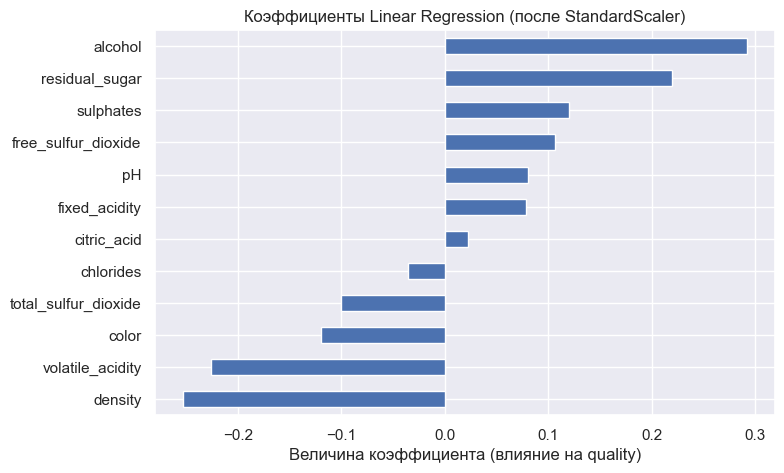

In [7]:
coef = pd.Series(lin_reg.named_steps["model"].coef_, index=X.columns).sort_values()

plt.figure(figsize=(8, 5))
coef.plot(kind="barh")
plt.title("Коэффициенты Linear Regression (после StandardScaler)")
plt.xlabel("Величина коэффициента (влияние на quality)")
plt.show()

### Коэффициенты Linear Regression
После стандартизации StandardScaler |coef| отражает силу влияния.

**Топ**: 
1. alcohol (+0.33)
2. volatile acidity (−0.18)
3. sulphates (+0.15) — совпадает с корреляциями EDA.

<u>**Контрпример**</u> — citric acid: корреляция с quality +0.23, но коэффициент ≈ −0.019. Причина — мультиколлинеарность (citric acid ~ fixed acidity 0.67): линейная модель делит вклад между коррелированными признаками, и коэффициент отдельного признака может почти обнулиться и сменить знак.

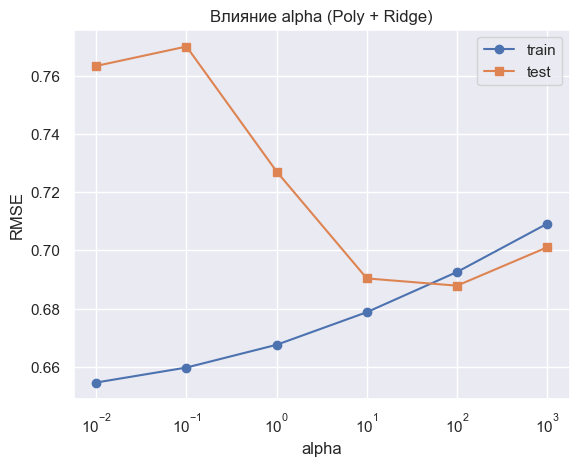

In [8]:
alphas = [0.01, 0.1, 1, 10, 100, 1000]
train_rmse, test_rmse = [], []
for a in alphas:
    p = Pipeline([("poly", PolynomialFeatures(best_degree, include_bias=False)),
                  ("scaler", StandardScaler()), ("model", Ridge(alpha=a))])
    p.fit(X_train, y_train)
    train_rmse.append(rmse(y_train, p.predict(X_train)))
    test_rmse.append(rmse(y_test, p.predict(X_test)))

plt.plot(alphas, train_rmse, "o-", label="train")
plt.plot(alphas, test_rmse, "s-", label="test")
plt.xscale("log"); plt.xlabel("alpha"); plt.ylabel("RMSE")
plt.legend(); plt.title("Влияние alpha (Poly + Ridge)")
plt.show()

График показывает CV RMSE (5 фолдов) полиномиальной регрессии (degree = 2, 77 признаков) в зависимости от alpha в Ridge
Шкала логарифмическая, так как альфа меняется на порядки (0.01 … 1000).

Итог: регуляризация улучшает CV-качество на 0.04 (0.702 → 0.662). Для сравнения: на исходных 11 признаках (degree = 1) альфа почти не меняет качество (CV ≈ 0.665 при alpha ≤ 10) — вся потребность в регуляризации создаётся именно полиномиальными признаками.

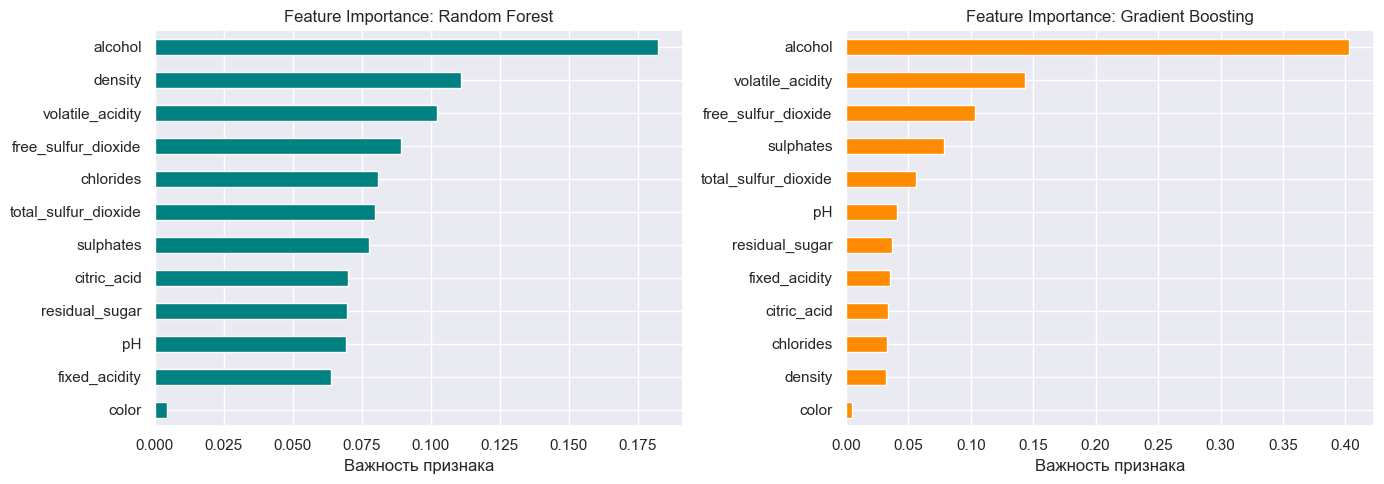

,Linear_Reg,Random_Forest,Gradient_Boosting
alcohol,0.2918,0.1823,0.4028
density,0.2528,0.1108,0.0319
volatile_acidity,0.2255,0.1022,0.1436
free_sulfur_dioxide,0.1061,0.0891,0.1036
chlorides,0.0356,0.0807,0.0329
total_sulfur_dioxide,0.1004,0.0799,0.0564
sulphates,0.1196,0.0777,0.0784
citric_acid,0.0221,0.0701,0.0339
residual_sugar,0.2192,0.0697,0.0366
pH,0.0807,0.0693,0.0405


In [9]:
rf_imp = pd.Series(rand_for.feature_importances_, index=X.columns).sort_values()
gb_imp = pd.Series(grad_boost.feature_importances_, index=X.columns).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

rf_imp.plot(kind="barh", ax=axes[0], color="teal")
axes[0].set_title("Feature Importance: Random Forest")
axes[0].set_xlabel("Важность признака")

gb_imp.plot(kind="barh", ax=axes[1], color="darkorange")
axes[1].set_title("Feature Importance: Gradient Boosting")
axes[1].set_xlabel("Важность признака")

plt.tight_layout()
plt.show()

imp_df = pd.DataFrame({
    "Linear_Reg": np.abs(lin_reg.named_steps["model"].coef_),
    "Random_Forest": rand_for.feature_importances_,
    "Gradient_Boosting": grad_boost.feature_importances_
}, index=X.columns).sort_values(by="Random_Forest", ascending=False)

display(imp_df.round(4))

### Важность признаков
Random Forest и Gradient Boosting. Оба графика показывают feature_importances_ — суммарную долю снижения ошибки, принесённую признаком, в среднем по деревьям. Топ-3 совпадает у обеих моделей и по составу, и по порядку.

Различие — в **концентрации**: GB отдаёт alcohol 30% общего веса (топ-3 в сумме 57%), а RF распределяет важность шире (alcohol 19%, топ-3 — 44%; density, chlorides и citric acid заметно выше, чем у GB). Причина: при каждом разбиении дерево RF видит лишь случайные 30% признаков (max_features = 0.3) и часто вынуждено использовать заменители — коррелирующие density и chlorides; GB же строит короткую последовательность мелких поправок и сосредоточивается на самых информативных разбиениях по alcohol.

Согласование с EDA и линейной регрессией. alcohol — признак №1 во всех четырёх источниках: корреляция +0.48, коэффициент LR +0.33, важности 0.19/0.30. volatile acidity (−0.40 / −0.18) и sulphates (+0.25 / +0.15) также в топе. Показательный контрпример — citric acid: в EDA у него 4-я корреляция с quality (+0.23), но LR-коэффициент ≈ −0.02, а важность в ансамблях всего 0.04–0.07: его связь с качеством в основном «повторяет» fixed acidity (r = 0.67), самостоятельного вклада при совместном использовании почти нет.

Можно ли на основании feature importance утверждать причинность? Нет. Важность измеряет вклад признака в предсказание, а не влияние на качество вина: 
1. между коррелирующими признаками важность делится произвольно (alcohol и density: r = −0.50 — часть «заслуг» alcohol может принадлежать density)
2. данные наблюдательные — мы не меняли показатели вина и не смотрели, как меняется оценка
3. на оценку влияют неучтённые факторы (сорт, регион, технология, субъективность дегустаторов). Причинность подтвердил бы только контролируемый эксперимент.

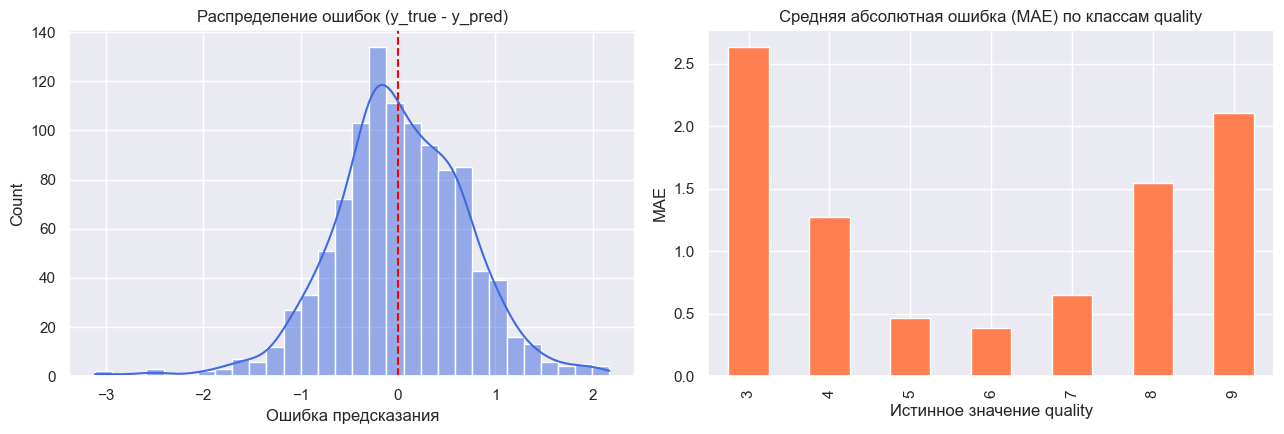

Качество модели Gradient Boosting в разрезе каждого значения quality:


,count,MAE,RMSE
y_true,,,
3,4,2.6343,2.6820
4,38,1.2707,1.3877
5,348,0.4693,0.5880
6,458,0.3834,0.4701
7,190,0.6463,0.7507
8,25,1.5457,1.5911
9,1,2.1015,2.1015


Топ-4 крупных ошибок:


,alcohol,sulphates,y_true,y_pred,error
4151,11.0,0.43,3,6.11,-3.11
1729,11.5,0.40,3,6.04,-3.04
4404,12.7,0.79,4,6.73,-2.73
718,9.9,0.86,3,5.53,-2.53
4423,12.0,0.65,4,6.50,-2.50


In [12]:
best_pred = grad_boost.predict(X_test)

error_df = X_test.copy()
error_df["y_true"] = y_test
error_df["y_pred"] = best_pred
error_df["error"] = error_df["y_true"] - error_df["y_pred"]
error_df["abs_error"] = np.abs(error_df["error"])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.histplot(error_df["error"], bins=30, kde=True, ax=axes[0], color="royalblue")
axes[0].axvline(0, color="red", linestyle="--")
axes[0].set_title("Распределение ошибок (y_true - y_pred)")
axes[0].set_xlabel("Ошибка предсказания")

quality_errors = error_df.groupby("y_true").agg(
    count=("abs_error", "count"),
    MAE=("abs_error", "mean"),
    RMSE=("error", lambda e: np.sqrt(np.mean(e**2)))
)
quality_errors["MAE"].plot(kind="bar", ax=axes[1], color="coral")
axes[1].set_title("Средняя абсолютная ошибка (MAE) по классам quality")
axes[1].set_xlabel("Истинное значение quality")
axes[1].set_ylabel("MAE")

plt.tight_layout()
plt.show()

print("Качество модели Gradient Boosting в разрезе каждого значения quality:")
display(quality_errors.round(4))

print("Топ-4 крупных ошибок:")
cols = ["alcohol", "sulphates", "y_true", "y_pred", "error"]
display(error_df.loc[error_df["error"].abs().sort_values(ascending=False).index[:5], cols].round(2))

## Финальные выводы

#### Задача и данные
Решалась задача регрессии качества красного вина (Wine Quality) по 11 химическим показателям. После удаления 240 дубликатов осталось 1359 объектов, пропусков нет. Целевая quality дискретна (3–8), 82% вин — классы 5–6, крайние оценки редки (3 и 8 — 27 вин, ~2%).

#### Методология
Разбиение 80/20 (1087/272, random_state = 42) — единый тестовый набор для всех моделей. Качество оценивалось по RMSE (основная метрика) и MAE на тесте, плюс 5-блочная кросс-валидация на обучающей выборке.

#### Baseline и порог
Константное предсказание (среднее 5.64) даёт RMSE 0.844 / MAE 0.705. Порог работы RMSE < 0.70 прошли все обученные модели. Лучшая — Gradient Boosting: RMSE 0.614, MAE 0.475 (−27% и −33% к baseline). Random Forest статистически неотличим (0.616 / 0.468), а по кросс-валидации даже лучше (0.651 против 0.666).

#### Что показали модели
Порядок результатов объясняется формой зависимости: линейная регрессия хуже всех (0.657) — качество связано с признаками нелинейно и через взаимодействия, которые гиперплоскость описать не может. Явное добавление полиномов (Poly + Ridge, degree = 2, 77 признаков, alpha = 100) закрывает часть разрыва (0.637), ансамбли делают то же автоматически и лучше всех (0.614–0.616). Регуляризация в Poly-модели обязательна: без неё CV-качество хуже на 0.04, а при degree = 3 (363 признака) модель и вовсе разваливается (CV до 1.70).

#### Анализ ошибок
Медианная ошибка финальной модели — 0.39 балла, у 65% вин |e| ≤ 0.5. Систематический паттерн — регрессия к среднему на редких классах: вина quality 3 модель в среднем оценивает в 4.8, quality 8 — в 6.7 (таких вин в train — 6 и 14 соответственно). Худшие 5% объектов дают 35% суммы квадратов ошибок.

#### Ограничения
MAE ≈ 0.47 близка к естественному «полу» задачи: соседние оценки субъективны даже для дегустаторов, поэтому шум разметки ограничивает достижимую точность. Дальнейший рост качества возможен скорее за счёт внешних данных (сорт, регион, год), а не настройки моделей.

### Итог
Пройден полный цикл: EDA → baseline → четыре модели с честным сравнением на едином тесте → интерпретация коэффициентов и важностей → анализ ошибок. Все модели превзошли baseline, порог RMSE < 0.70 выполнен, финальная модель — Gradient Boosting.